In [ ]:
import numpy as np
import pandas as pd
import datetime
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import colors
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler
from sklearn.decomposition import PCA
from yellowbrick.cluster import KElbowVisualizer
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt, numpy as np
from mpl_toolkits.mplot3d import Axes3D
from sklearn.cluster import AgglomerativeClustering
from matplotlib.colors import ListedColormap
from sklearn import metrics
import warnings
import sys
if not sys.warnoptions:
    warnings.simplefilter("ignore")
np.random.seed(42)
import warnings
warnings.filterwarnings('ignore')
from sklearn.cluster import AffinityPropagation
from sklearn.metrics import silhouette_score

In [ ]:
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams['font.family'] = 'DejaVu Sans'
mpl.rcParams['axes.unicode_minus'] = False

In [ ]:
!gdown 1nrZqblTbq9PHYvafZIi9giisKIdXmn34

Downloading...
From: https://drive.google.com/uc?id=1nrZqblTbq9PHYvafZIi9giisKIdXmn34
To: /content/raw.csv
100% 218k/218k [00:00<00:00, 60.8MB/s]


In [ ]:
df = pd.read_csv(r'/content/raw.csv')
df

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,4/9/2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,8/3/2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21/8/2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10/2/2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19/1/2014,94,173,...,5,0,0,0,0,0,0,3,11,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,10870,1967,Graduation,Married,61223.0,0,1,13/6/2013,46,709,...,5,0,0,0,0,0,0,3,11,0
2236,4001,1946,PhD,Together,64014.0,2,1,10/6/2014,56,406,...,7,0,0,0,1,0,0,3,11,0
2237,7270,1981,Graduation,Divorced,56981.0,0,0,25/1/2014,91,908,...,6,0,1,0,0,0,0,3,11,0
2238,8235,1956,Master,Together,69245.0,0,1,24/1/2014,8,428,...,3,0,0,0,0,0,0,3,11,0


###**Xử lí nhanh**

In [ ]:
df = df.drop(columns=['Z_CostContact', 'Z_Revenue','ID'])

In [ ]:
## Số giá trị null không nhiều, outliers cũng ít ảnh hưởng điền bằng median
#chỉ có 1 giá trị 800.000 còn lại dưới 200.000
df['Income'].fillna(df['Income'].median(), inplace=True)
df = df[df.Income <= 200000]

People

In [ ]:
#chuyển Year-Birth thành tuổi
df['Year_Birth']= 2025 - df['Year_Birth']
df.Year_Birth

,Year_Birth
0,68
1,71
2,60
3,41
4,44
...,...
2235,58
2236,79
2237,44
2238,69


In [ ]:
#lấy những người bé hơn 90 tuổi để loại bỏ Outliers
df =df[df.Year_Birth<=90]

In [ ]:
df.Marital_Status = df.Marital_Status.replace(['Alone', 'YOLO'], 'Single')
#bỏ giá trị Absurd vì số lượng nhỏ và không có ý nghĩa
df = df[df.Marital_Status != 'Absurd']
df.Marital_Status.value_counts()

,count
Marital_Status,
Married,864
Together,578
Single,484
Divorced,231
Widow,77


In [ ]:
df['Children'] = df['Kidhome'] + df['Teenhome']
df.drop(columns=['Kidhome', 'Teenhome'], inplace=True)

In [ ]:
df['Dt_Customer']= pd.to_datetime(df['Dt_Customer'], format='%d/%m/%Y')

#Chuyển thành số tháng từ khi đăng kí đến nay
df['Customer_for'] = (datetime.datetime.now() - df['Dt_Customer']).dt.days // 30
df.drop(columns=['Dt_Customer'], inplace=True)

In [ ]:
#Có khiếu nại không
df.Complain.value_counts()
#có 19 người khiếu nại thôi feature này bỏ luôn vì nó sấp xỉ 1 giá trị
df = df.drop(columns=['Complain'])

Product

In [ ]:
#Nhận xét phân phối, giá trị nhiều outliers theo boxplot nhưng hợp thực tế logic -> không loại bỏ vì không phải giá trị ngoại lai đúng nghĩa

Promotion

In [ ]:
#gom thành 3 nhóm cho hợp lí 1: mua ít, 2: mua vừa, 3: mua nhiều
def categorize_deals_purchases(x):
    if x <= 2:
        return 1          # 0-2 deals (0,1,2)
    elif x <= 5:
        return 2        # 3-5 deals (3,4,5)
    else:
        return 3       # 6+ deals (6,7,8,9,...)

df['NumDealsPurchases'] = df['NumDealsPurchases'].apply(categorize_deals_purchases)

In [ ]:
df = df.drop(columns=['AcceptedCmp1','AcceptedCmp2','AcceptedCmp3','AcceptedCmp4','AcceptedCmp5','Response'])  #bỏ để tránh nhiễu và vì các giá trị lấn át quá nhiều nên không có ý nghĩa phân loại

Place

In [ ]:
#Có outliers nhưng không bỏ vì mọi điểm đó là giá trị hợp lí trong thực tế

In [ ]:
##lưu temp để tìm tri thức cụm
temp = df.copy()

### **Chuẩn hóa**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2234 entries, 0 to 2239
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Year_Birth           2234 non-null   int64  
 1   Education            2234 non-null   object 
 2   Marital_Status       2234 non-null   object 
 3   Income               2234 non-null   float64
 4   Recency              2234 non-null   int64  
 5   MntWines             2234 non-null   int64  
 6   MntFruits            2234 non-null   int64  
 7   MntMeatProducts      2234 non-null   int64  
 8   MntFishProducts      2234 non-null   int64  
 9   MntSweetProducts     2234 non-null   int64  
 10  MntGoldProds         2234 non-null   int64  
 11  NumDealsPurchases    2234 non-null   int64  
 12  NumWebPurchases      2234 non-null   int64  
 13  NumCatalogPurchases  2234 non-null   int64  
 14  NumStorePurchases    2234 non-null   int64  
 15  NumWebVisitsMonth    2234 non-null   int64 

In [ ]:
num = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
cate = df.select_dtypes(include=['object']).columns.tolist()

In [ ]:
# Xử lý Ordinal Encoding cho Education
education_order = ['Basic', '2n Cycle', 'Graduation', 'Master', 'PhD']
education_mapping = {level: idx for idx, level in enumerate(education_order)}
df['Education'] = df['Education'].map(education_mapping)

In [ ]:
df = pd.get_dummies(df, columns=['Marital_Status'], drop_first=True)  #one-hot cho nominal

In [ ]:
binary_cols = []
continuous_cols = []

for col in num:  # chỉ xét trong num
    uniq = df[col].dropna().unique()
    if len(uniq) == 2 and set(uniq) == {0, 1}:
        binary_cols.append(col)
    else:
        continuous_cols.append(col)

print("Binary columns:", binary_cols)
print("Continuous columns:", continuous_cols)


Binary columns: []
Continuous columns: ['Year_Birth', 'Income', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'Children', 'Customer_for']


In [ ]:
#Không có biến binary, nên scale bằng Robust do nhiều Outliers
df_scaled = df.copy()
scaler = RobustScaler()

df_scaled[continuous_cols] = scaler.fit_transform(df[continuous_cols])



In [ ]:

ap = AffinityPropagation(damping=0.9, random_state=42,preference = -3000)  #-2200 là cụm
labels = ap.fit_predict(df_scaled)

n_clusters = len(set(labels))

if n_clusters > 1:
    sil_score = silhouette_score(df_scaled, labels, metric='euclidean')
else:
    sil_score = None

print(f"Số cluster tìm được: {n_clusters}")
print(f"Silhouette Score: {sil_score}")
df_scaled['AP_Cluster'] = labels

Số cluster tìm được: 2
Silhouette Score: 0.3526801260101285


### **PCA và Chạy AP**

In [ ]:
data = df_scaled.copy()

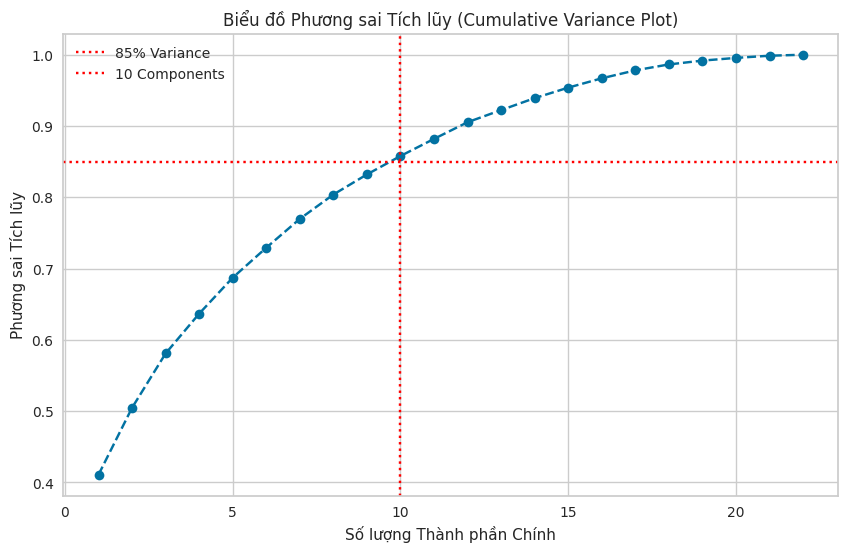

Số thành phần cần thiết để giữ 85% phương sai: 10


In [ ]:
pca_full = PCA(n_components=None)
pca_full.fit(data)

# Tính phương sai tích lũy
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)
k = np.argmax(cumulative_variance >= 0.85)+1


plt.figure(figsize=(10, 6))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--')
plt.title('Biểu đồ Phương sai Tích lũy (Cumulative Variance Plot)')
plt.xlabel('Số lượng Thành phần Chính')
plt.ylabel('Phương sai Tích lũy')
plt.grid(True)


plt.axhline(y=0.85, color='red', linestyle=':', label='85% Variance')
plt.axvline(x=k, color='red', linestyle=':', label=f'{k} Components')
plt.legend(loc='best')
plt.show()

print(f"Số thành phần cần thiết để giữ 85% phương sai: {k}")

In [ ]:
#lấy >80% nên lấy k=10 khoảng 85%
k_components = k

pca_final = PCA(n_components=k_components)
X_pca = pca_final.fit_transform(data)

print(f"Đã giảm chiều dữ liệu từ {data.shape[1]} xuống {X_pca.shape[1]} thành phần.")

Đã giảm chiều dữ liệu từ 22 xuống 10 thành phần.


**CHỌN THAM SỐ PREFERENCE TỐI ƯU**

In [ ]:
# Ước chừng khoảng của tham số prefernce
from sklearn.metrics.pairwise import euclidean_distances

distance_matrix = -euclidean_distances(X_pca)**2

distance_values = distance_matrix[np.triu_indices_from(distance_matrix, k=1)]

print("THỐNG KÊ MA TRẬN PREFERENCE (-euclidean²):")
print("=" * 50)
print(f"Min:    {np.min(distance_values):.2f}")
print(f"Q1:     {np.percentile(distance_values, 25):.2f}")
print(f"Median: {np.median(distance_values):.2f}")
print(f"Q3:     {np.percentile(distance_values, 75):.2f}")
print(f"Max:    {np.max(distance_values):.2f}")

THỐNG KÊ MA TRẬN PREFERENCE (-euclidean²):
Min:    -262.36
Q1:     -32.52
Median: -17.20
Q3:     -8.23
Max:    -0.00


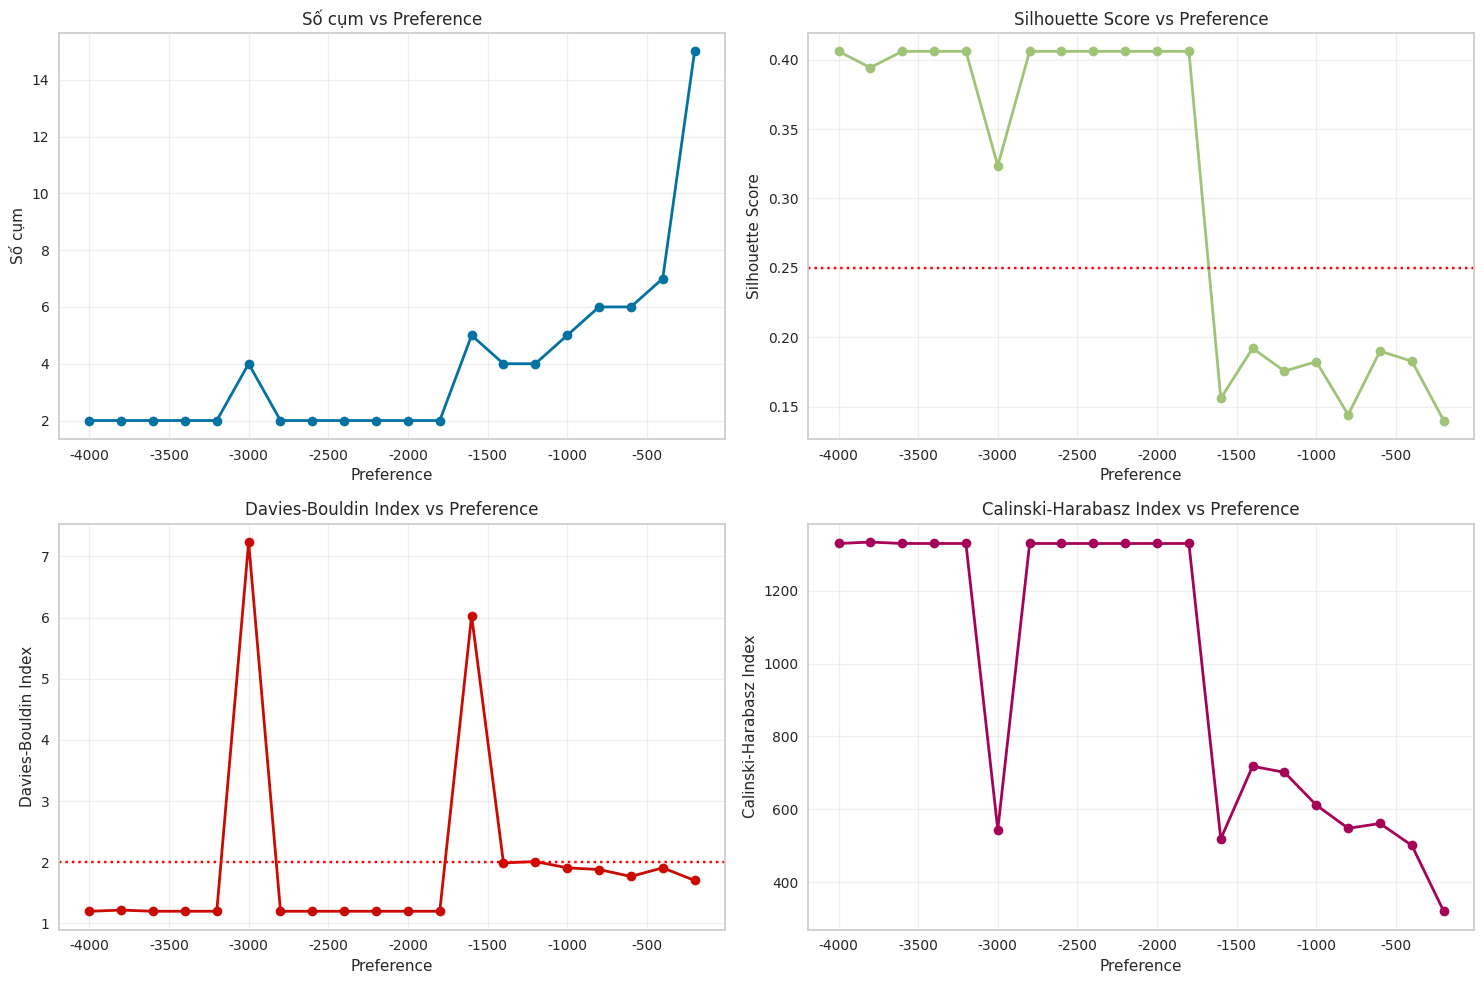

KẾT QUẢ TỐT NHẤT THEO TỪNG CHỈ SỐ:
Silhouette tốt nhất: 0.4059
   Preference: -4000.00, Số cụm: 2.0
Davies-Bouldin tốt nhất: 1.1990
   Preference: -4000.00, Số cụm: 2.0
Calinski-Harabasz tốt nhất: 1333.7334
   Preference: -3800.00, Số cụm: 2.0

 DATAFRAME KẾT QUẢ:
    preference  n_clusters  silhouette  davies_bouldin  calinski_harabasz
0        -4000           2      0.4059          1.1990          1329.8129
1        -3800           2      0.3942          1.2179          1333.7334
2        -3600           2      0.4059          1.1990          1329.8129
3        -3400           2      0.4059          1.1990          1329.8129
4        -3200           2      0.4059          1.1990          1329.8129
5        -3000           4      0.3236          7.2340           543.8511
6        -2800           2      0.4059          1.1990          1329.8129
7        -2600           2      0.4059          1.1990          1329.8129
8        -2400           2      0.4059          1.1990          1329.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import AffinityPropagation
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

def evaluate_ap_with_preferences(X, preference_range):

    results = []

    for pref in preference_range:
        try:
            ap = AffinityPropagation(
                preference=pref,
                damping=0.9,
                max_iter=1000,
                random_state=42
            )
            labels = ap.fit_predict(X)
            n_clusters = len(np.unique(labels))

            # Chỉ tính metrics nếu có ít nhất 2 cụm
            if n_clusters > 1 and n_clusters < len(X):
                silhouette = silhouette_score(X, labels)
                db_index = davies_bouldin_score(X, labels)
                ch_index = calinski_harabasz_score(X, labels)
            else:
                silhouette = db_index = ch_index = np.nan

            results.append({
                'preference': pref,
                'n_clusters': n_clusters,
                'silhouette': silhouette,
                'davies_bouldin': db_index,
                'calinski_harabasz': ch_index
            })

        except Exception as e:
            print(f"Lỗi với preference {pref}: {e}")
            continue

    return pd.DataFrame(results)

# Tạo dải preference (thay đổi range theo nhu cầu)
preference_range = range(-4000,0,200)
# Chạy đánh giá
results_df = evaluate_ap_with_preferences(X_pca, preference_range)

# Vẽ biểu đồ so sánh
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 10))

# 1. Số cụm vs Preference
ax1.plot(results_df['preference'], results_df['n_clusters'], 'bo-', linewidth=2)
ax1.set_xlabel('Preference')
ax1.set_ylabel('Số cụm')
ax1.set_title('Số cụm vs Preference')
ax1.grid(True, alpha=0.3)

# 2. Silhouette Score vs Preference
ax2.plot(results_df['preference'], results_df['silhouette'], 'go-', linewidth=2)
ax2.set_xlabel('Preference')
ax2.set_ylabel('Silhouette Score')
ax2.axhline(y=0.25, color='red', linestyle=':')
ax2.set_title('Silhouette Score vs Preference')
ax2.grid(True, alpha=0.3)

# 3. Davies-Bouldin Index vs Preference
ax3.plot(results_df['preference'], results_df['davies_bouldin'], 'ro-', linewidth=2)
ax3.set_xlabel('Preference')
ax3.set_ylabel('Davies-Bouldin Index')
ax3.axhline(y=2, color='red', linestyle=':')
ax3.set_title('Davies-Bouldin Index vs Preference')
ax3.grid(True, alpha=0.3)

# 4. Calinski-Harabasz Index vs Preference
ax4.plot(results_df['preference'], results_df['calinski_harabasz'], 'mo-', linewidth=2)
ax4.set_xlabel('Preference')
ax4.set_ylabel('Calinski-Harabasz Index')
ax4.set_title('Calinski-Harabasz Index vs Preference')
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Hiển thị kết quả tốt nhất
print("KẾT QUẢ TỐT NHẤT THEO TỪNG CHỈ SỐ:")
print("=" * 50)

# Silhouette tốt nhất
best_sil = results_df.loc[results_df['silhouette'].idxmax()]
print(f"Silhouette tốt nhất: {best_sil['silhouette']:.4f}")
print(f"   Preference: {best_sil['preference']:.2f}, Số cụm: {best_sil['n_clusters']}")

# Davies-Bouldin tốt nhất (nhỏ nhất)
best_db = results_df.loc[results_df['davies_bouldin'].idxmin()]
print(f"Davies-Bouldin tốt nhất: {best_db['davies_bouldin']:.4f}")
print(f"   Preference: {best_db['preference']:.2f}, Số cụm: {best_db['n_clusters']}")

# Calinski-Harabasz tốt nhất
best_ch = results_df.loc[results_df['calinski_harabasz'].idxmax()]
print(f"Calinski-Harabasz tốt nhất: {best_ch['calinski_harabasz']:.4f}")
print(f"   Preference: {best_ch['preference']:.2f}, Số cụm: {best_ch['n_clusters']}")

print("\n DATAFRAME KẾT QUẢ:")
print(results_df.head(20).round(4))


AP hoàn tất sau 7.23 giây.
Số cụm (exemplars) tìm thấy: 2
Silhouette Score: 0.4059


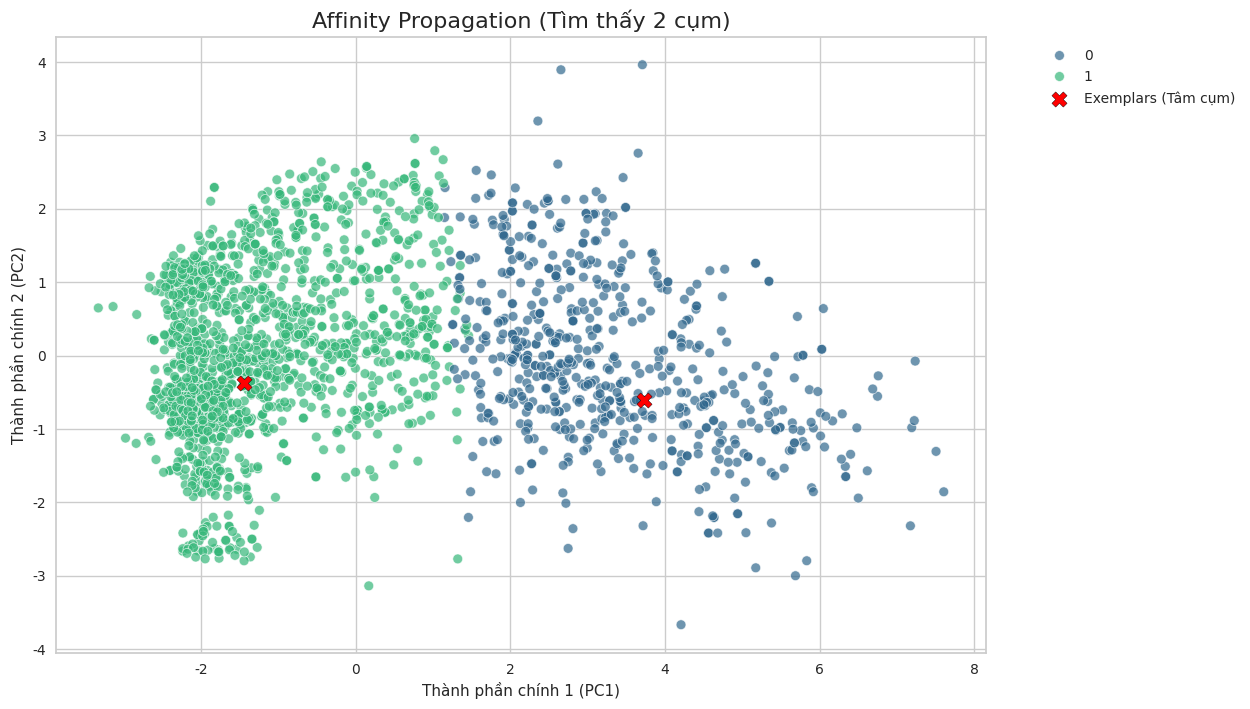

In [ ]:
from sklearn.cluster import AffinityPropagation
from sklearn.metrics import silhouette_score
import time
start_time = time.time()

# Khởi tạo AP
ap = AffinityPropagation(damping=0.9,random_state=42, preference=-1800)  #dựa vào đánh giá trên chọn preference = -1800

# Fit mô hình
ap.fit(X_pca)

end_time = time.time()

# Lấy kết quả
ap_labels = ap.labels_
ap_centers_indices = ap.cluster_centers_indices_
ap_n_clusters = len(ap_centers_indices)

print(f"\nAP hoàn tất sau {end_time - start_time:.2f} giây.")
print(f"Số cụm (exemplars) tìm thấy: {ap_n_clusters}")

# Đánh giá
if ap_n_clusters > 1:
    score = silhouette_score(X_pca, ap_labels)
    print(f"Silhouette Score: {score:.4f}")
else:
    print("AP chỉ tìm thấy 1 cụm, không thể tính Silhouette Score.")


# Lấy tọa độ tâm cụm (exemplars)
ap_centers_pca = ap.cluster_centers_

# Tạo DataFrame để vẽ
df_pca_results = pd.DataFrame(X_pca, columns=[f'PC{i+1}' for i in range(k_components)])
df_pca_results['AP_Cluster'] = ap_labels

# Vẽ
plt.figure(figsize=(12, 8))
sns.scatterplot(data=df_pca_results, x='PC1', y='PC2', hue='AP_Cluster',
                palette='viridis', legend='full', s=50, alpha=0.7)

# Vẽ các tâm cụm
plt.scatter(ap_centers_pca[:, 0], ap_centers_pca[:, 1], s=120, c='red',
            marker='X', label='Exemplars (Tâm cụm)', edgecolors='black')

plt.title(f'Affinity Propagation (Tìm thấy {ap_n_clusters} cụm)', fontsize=16)
plt.xlabel('Thành phần chính 1 (PC1)')
plt.ylabel('Thành phần chính 2 (PC2)')
plt.legend(bbox_to_anchor=(1.05, 1), loc=2)
plt.grid(True)
plt.show()

## **ĐÀO SÂU ĐẶC ĐIỂM CỤM**

In [ ]:
ap = temp.copy()# tạo df để tìm tri thức
# bỏ labels vào
ap['ap']=ap_labels


In [ ]:
ap.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2234 entries, 0 to 2239
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Year_Birth           2234 non-null   int64  
 1   Education            2234 non-null   object 
 2   Marital_Status       2234 non-null   object 
 3   Income               2234 non-null   float64
 4   Recency              2234 non-null   int64  
 5   MntWines             2234 non-null   int64  
 6   MntFruits            2234 non-null   int64  
 7   MntMeatProducts      2234 non-null   int64  
 8   MntFishProducts      2234 non-null   int64  
 9   MntSweetProducts     2234 non-null   int64  
 10  MntGoldProds         2234 non-null   int64  
 11  NumDealsPurchases    2234 non-null   int64  
 12  NumWebPurchases      2234 non-null   int64  
 13  NumCatalogPurchases  2234 non-null   int64  
 14  NumStorePurchases    2234 non-null   int64  
 15  NumWebVisitsMonth    2234 non-null   int64 

In [ ]:
#số lượng mỗi nhóm
ap.ap.value_counts()

,count
ap,
1,1607
0,627


In [ ]:
#chia biến theo loại để xử lí
people = [
     'Year_Birth', 'Education', 'Marital_Status', 'Income',
    'children', 'Customer_for', 'Recency',
]

product = [
    'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts',
    'MntSweetProducts', 'MntGoldProds'
]


place = [
    'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases',
    'NumWebVisitsMonth','NumDealsPurchases'
]

###PEOPLE

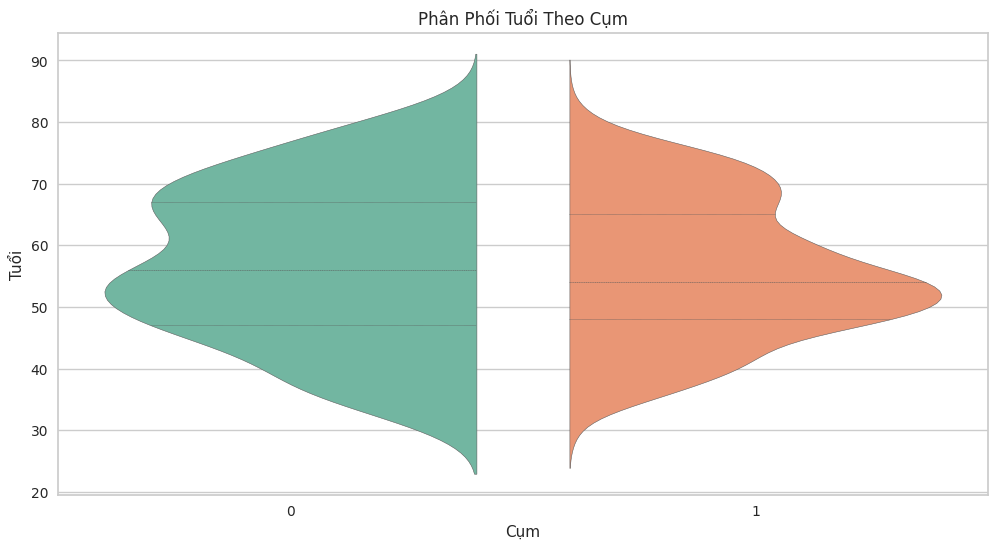

In [ ]:
plt.figure(figsize=(12, 6))
sns.violinplot(x='ap', y='Year_Birth', data=ap, split=True, palette='Set2', width=0.8,inner='quartile')
plt.title('Phân Phối Tuổi Theo Cụm')
plt.xlabel('Cụm')
plt.ylabel('Tuổi')
plt.show()


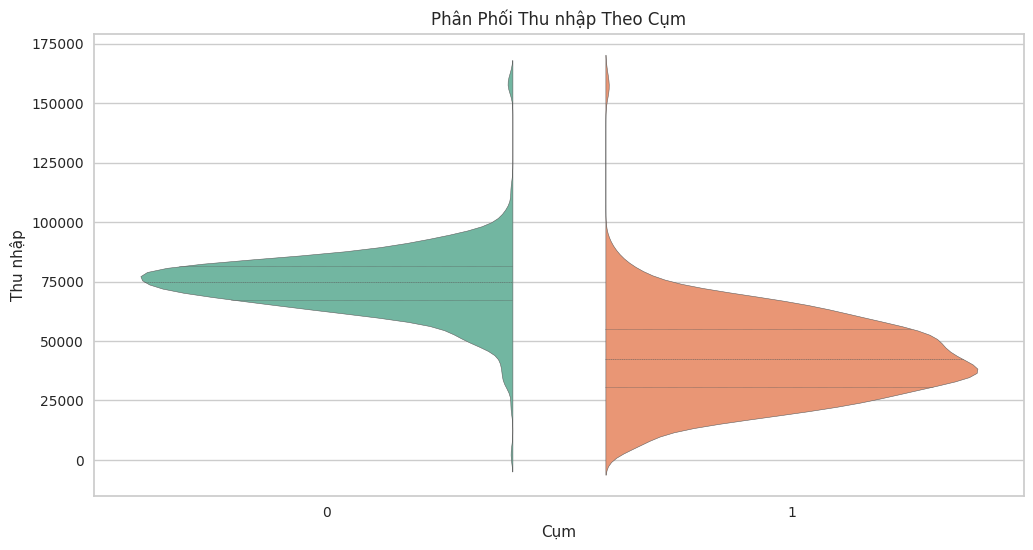

In [ ]:
#Thu nhập
plt.figure(figsize=(12, 6))
sns.violinplot(x='ap', y='Income', data=ap, split=True, palette='Set2', width=0.8, inner='quartile')
plt.title('Phân Phối Thu nhập Theo Cụm')
plt.xlabel('Cụm')
plt.ylabel('Thu nhập')
plt.show()


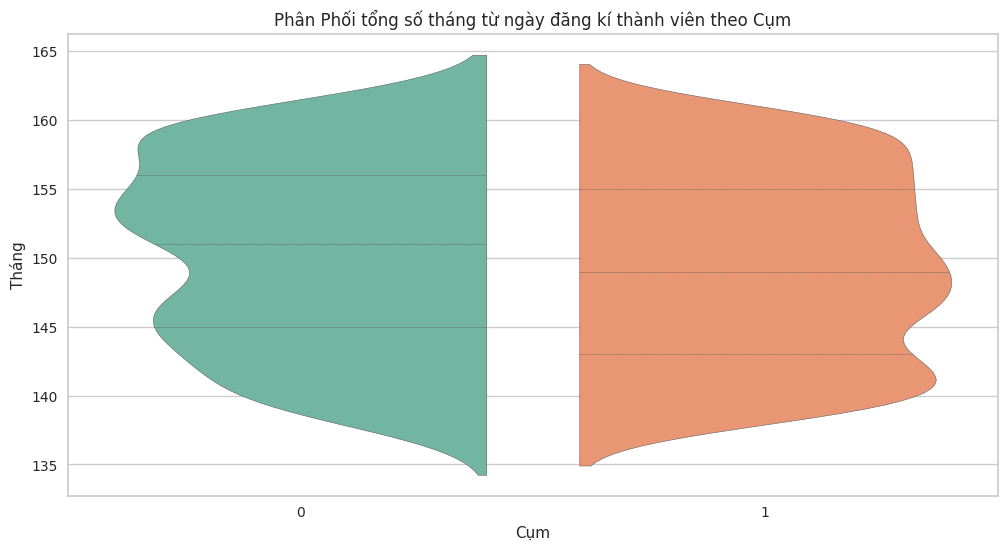

In [ ]:
#Thời gian từ ngày trở thành thành viên
plt.figure(figsize=(12, 6))
sns.violinplot(x='ap', y='Customer_for', data=ap, split=True, palette='Set2', width=0.8, inner='quartile')
plt.title('Phân Phối tổng số tháng từ ngày đăng kí thành viên theo Cụm')
plt.xlabel('Cụm')
plt.ylabel('Tháng')
plt.show()


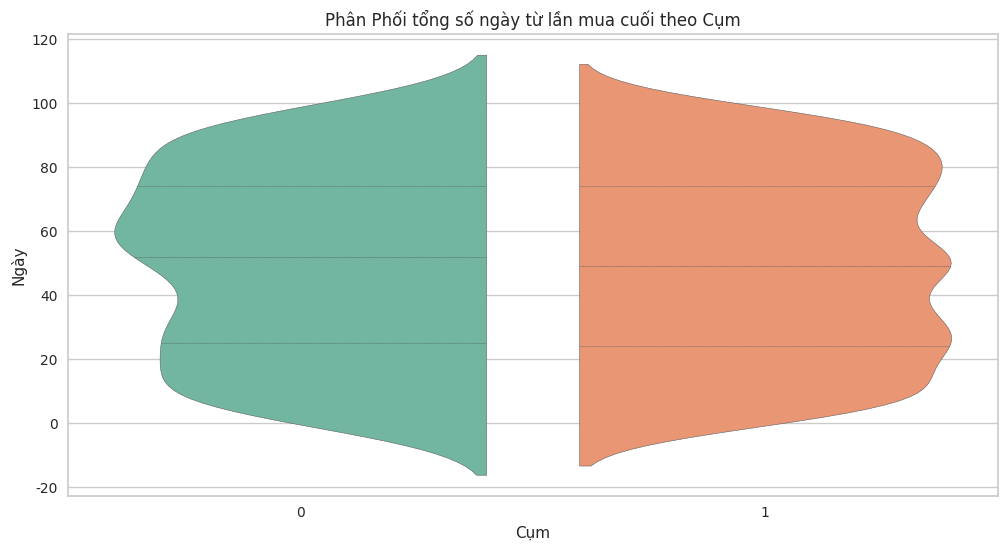

In [ ]:
#Số ngày từ lần mua cuối
plt.figure(figsize=(12, 6))
sns.violinplot(x='ap', y='Recency', data=ap, split=True, palette='Set2', width=0.8, inner='quartile')
plt.title('Phân Phối tổng số ngày từ lần mua cuối theo Cụm')
plt.xlabel('Cụm')
plt.ylabel('Ngày')
plt.show()


<Figure size 1400x800 with 0 Axes>

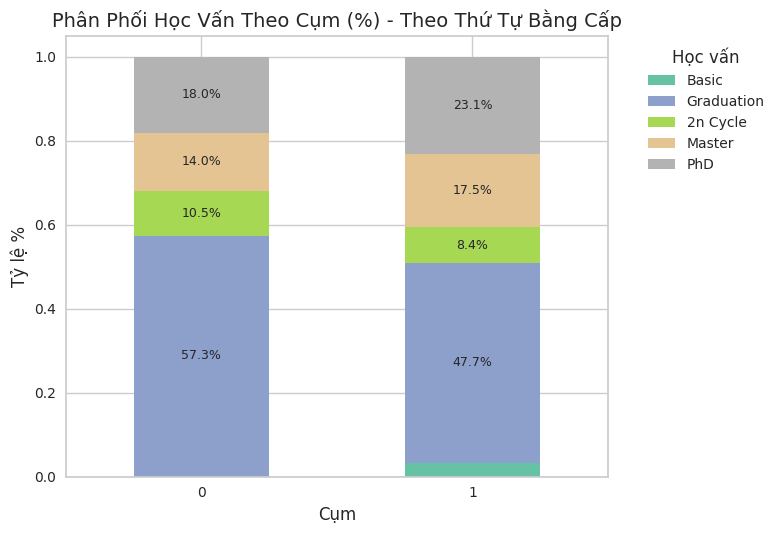

In [ ]:

# Định nghĩa thứ tự bằng cấp
education_order = ['Basic', 'Graduation','2n Cycle','Master', 'PhD']

cross_tab = pd.crosstab(ap['ap'], ap['Education'], normalize='index')[education_order]

plt.figure(figsize=(14, 8))
ax = cross_tab.plot(kind='bar', stacked=True, colormap='Set2')

plt.title('Phân Phối Học Vấn Theo Cụm (%) - Theo Thứ Tự Bằng Cấp', fontsize=14)
plt.xlabel('Cụm', fontsize=12)
plt.ylabel('Tỷ lệ %', fontsize=12)
plt.xticks(rotation=0)


for container in ax.containers:
    # Hiển thị label nếu tỷ lệ > 5%
    labels = [f'{v.get_height():.1%}' if v.get_height() > 0.05 else '' for v in container]
    ax.bar_label(container, labels=labels, label_type='center', fontsize=9)

plt.legend(title='Học vấn', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

<Figure size 1200x600 with 0 Axes>

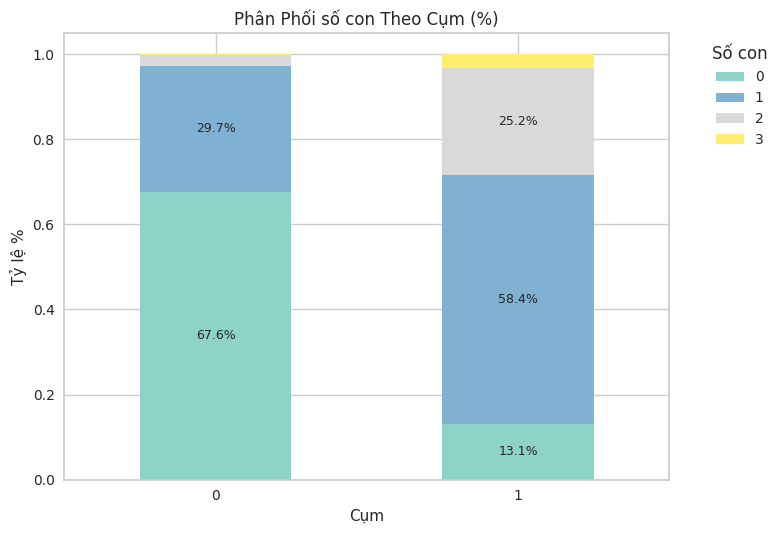

In [ ]:
#children
cr = pd.crosstab(ap['ap'], ap['Children'], normalize='index')

plt.figure(figsize=(12, 6))
ax = cr.plot(kind='bar', stacked=True, colormap='Set3')
plt.title('Phân Phối số con Theo Cụm (%)')
plt.xlabel('Cụm')
plt.ylabel('Tỷ lệ %')
plt.xticks(rotation=0)
# Thêm tỷ lệ % lên biểu đồ
for container in ax.containers:
    labels = [f'{v.get_height():.1%}' if v.get_height() > 0.05 else '' for v in container]
    ax.bar_label(container, labels=labels, label_type='center', fontsize=9)
plt.legend(title='Số con', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


<Figure size 1200x600 with 0 Axes>

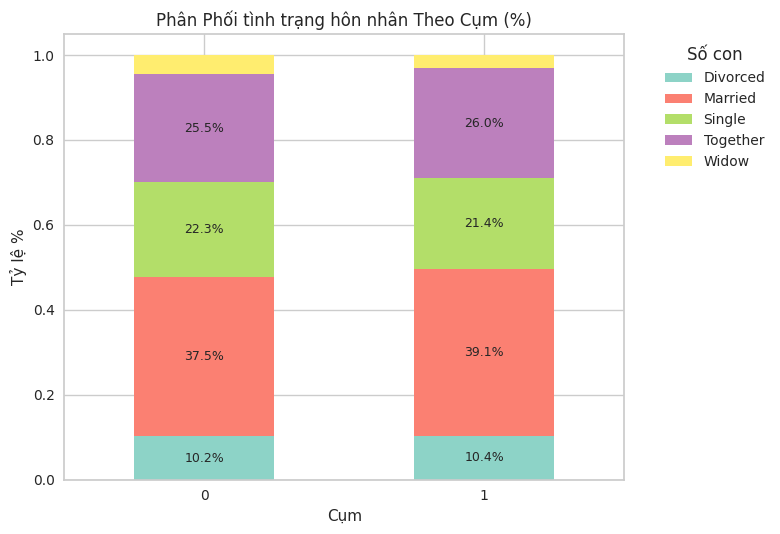

In [ ]:
cr = pd.crosstab(ap['ap'], ap['Marital_Status'], normalize='index')

plt.figure(figsize=(12, 6))
ax = cr.plot(kind='bar', stacked=True, colormap='Set3')
plt.title('Phân Phối tình trạng hôn nhân Theo Cụm (%)')
plt.xlabel('Cụm')
plt.ylabel('Tỷ lệ %')
plt.xticks(rotation=0)
# Thêm tỷ lệ % lên biểu đồ
for container in ax.containers:
    labels = [f'{v.get_height():.1%}' if v.get_height() > 0.05 else '' for v in container]
    ax.bar_label(container, labels=labels, label_type='center', fontsize=9)
plt.legend(title='Số con', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


### PRODUCT

In [ ]:
product

['MntWines',
 'MntFruits',
 'MntMeatProducts',
 'MntFishProducts',
 'MntSweetProducts',
 'MntGoldProds']

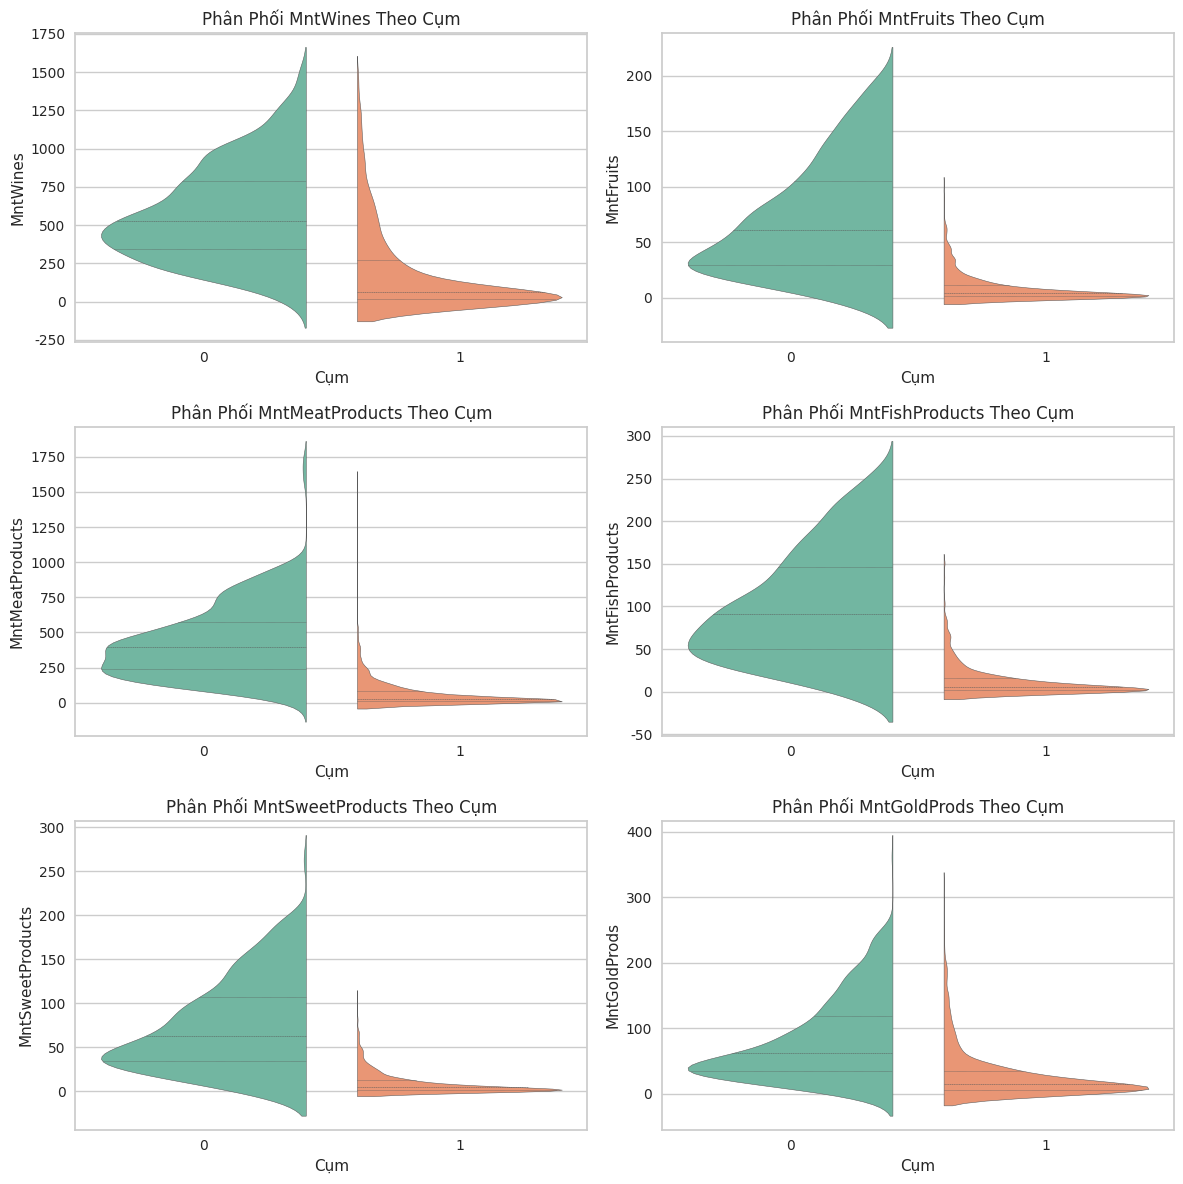

In [ ]:
plt.figure(figsize=(12, 12))
for col in product:
    plt.subplot(3, 2, product.index(col) + 1)
    sns.violinplot(x='ap', y=col, data=ap, split=True, palette='Set2', width=0.8, inner='quartile')
    plt.title(f'Phân Phối {col} Theo Cụm')
    plt.xlabel('Cụm')
    plt.ylabel(col)
plt.tight_layout()
plt.show()

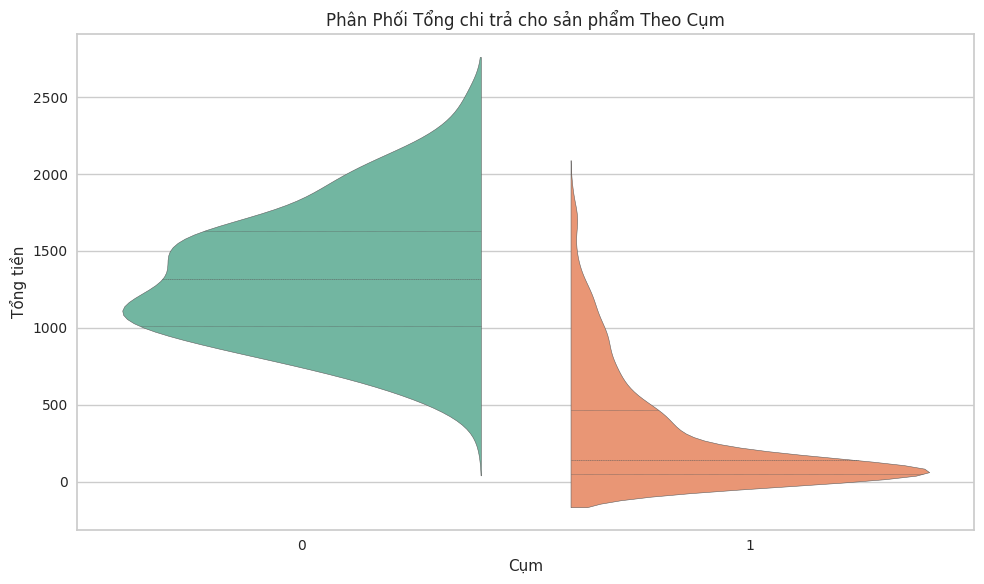

In [ ]:
# tổng số tiền chi trả cho sản phẩm theo cụm
ap['MntTotal']= ap[product].sum(axis=1)

plt.figure(figsize=(10, 6))
sns.violinplot(x='ap', y='MntTotal', data=ap, split=True, palette='Set2', width=0.8, inner='quartile')
plt.title(f'Phân Phối Tổng chi trả cho sản phẩm Theo Cụm')
plt.xlabel('Cụm')
plt.ylabel('Tổng tiền')
plt.tight_layout()
plt.show()

###PLACE

In [ ]:
place

['NumWebPurchases',
 'NumCatalogPurchases',
 'NumStorePurchases',
 'NumWebVisitsMonth',
 'NumDealsPurchases']

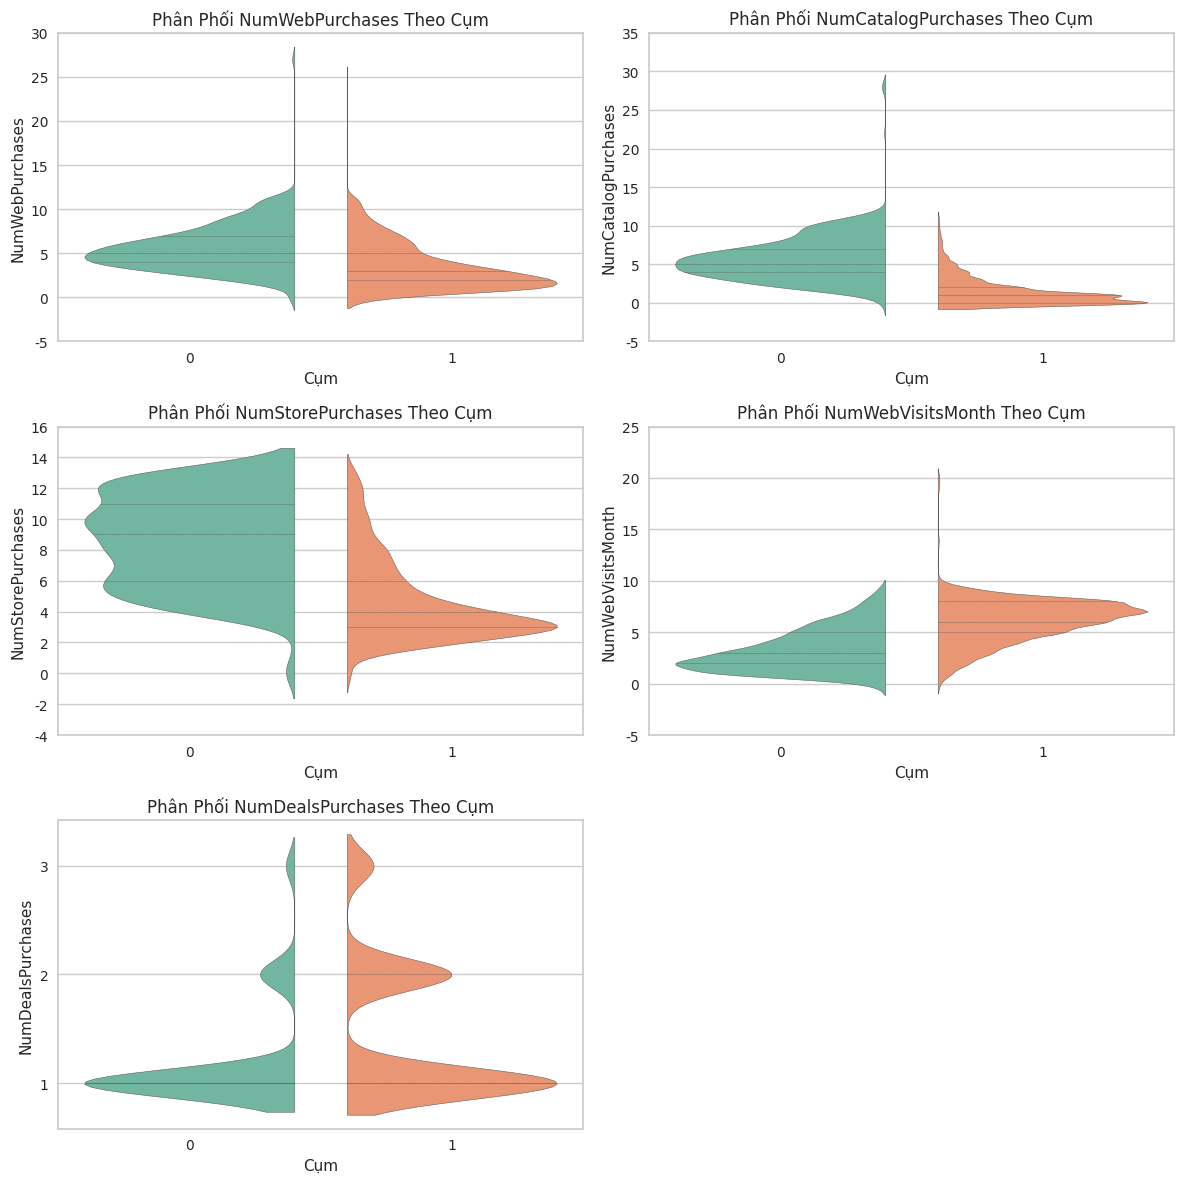

In [ ]:
plt.figure(figsize=(12, 12))
for col in place:
    plt.subplot(3, 2, place.index(col) + 1)
    sns.violinplot(x='ap', y=col, data=ap, split=True, palette='Set2', width=0.8, inner='quartile')
    plt.title(f'Phân Phối {col} Theo Cụm')
    plt.xlabel('Cụm')
    plt.ylabel(col)
    current_ticks = plt.yticks()[0]
    integer_ticks = [int(tick) for tick in current_ticks if tick.is_integer()]
    plt.yticks(integer_ticks)

plt.tight_layout()
plt.show()

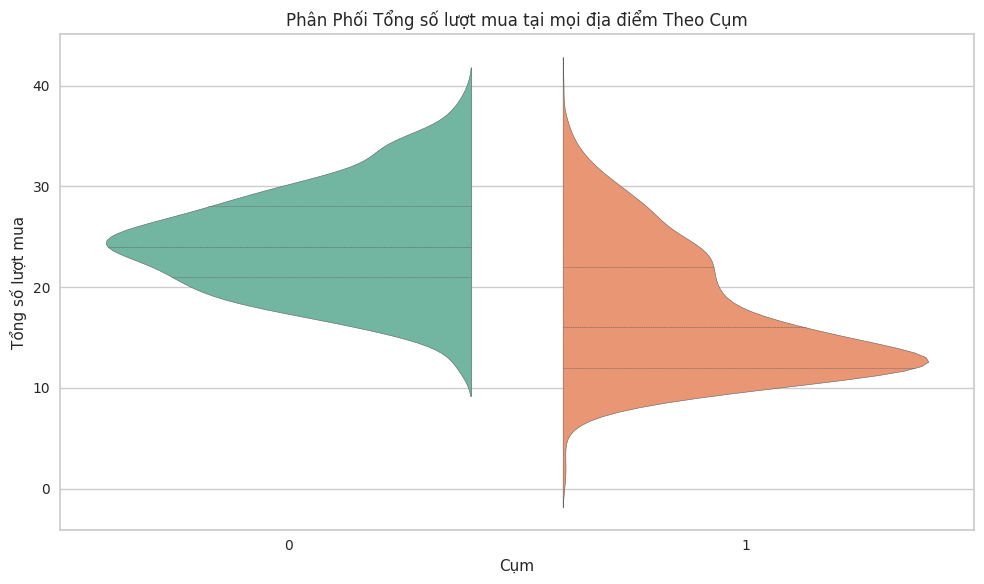

In [ ]:
#Tổng số lượng mua hàng ở mọi địa điểm
ap['NumTotal']= ap[place].sum(axis=1)

plt.figure(figsize=(10, 6))
sns.violinplot(x='ap', y='NumTotal', data=ap, split=True, palette='Set2', width=0.8, inner='quartile')
plt.title(f'Phân Phối Tổng số lượt mua tại mọi địa điểm Theo Cụm')
plt.xlabel('Cụm')
plt.ylabel('Tổng số lượt mua')
plt.tight_layout()
plt.show()
